# Assessing an order extract before analysis

We want to link order records, reconcile their values, and study churn. We first need to
establish which identifiers are reliable, which fields express the same information,
and which apparent relationships have supporting evidence.

The data are synthetic: 8,000 order records with known constraints, deliberate exceptions,
and an independent numeric control. This lets us check the library's findings against the
observations and the generating rules. The [companion module](onceover_example.py) contains
the fixed-seed data construction and table formatting. All profiling calls appear below.

In [1]:
import altair as alt
import onceover
import onceover_example as ex

alt.renderers.enable("svg")
orders = ex.orders_fixture(seed=2024)
report = onceover.profile(orders)

In [2]:
from IPython.display import Markdown
Markdown(report.to_markdown())

# onceover report

8000 rows × 17 columns (standard budget); key candidate: order_id; 8 functional dependencies, 15 predictive dependencies, 20 conditional rules

## Overview

- **rows × columns**: 8000 × 17
- **dtypes**: 1×date, 4×float64, 7×int64, 5×string
- **roles**: 10×categorical, 2×continuous, 1×date, 2×free_text, 2×identifier

## Findings

- **[0.9889·measured] dependencies/functional (value_mapping)** — double_quantity → quantity (quantity is a function of double_quantity; 0 violations in 8000 rows)
- **[0.9889·measured] dependencies/functional (affine)** — double_quantity = 2.000000·quantity within tolerance on all 8000 non-missing row pairs
- **[0.9889·measured] dependencies/functional (value_mapping)** — quantity → double_quantity (double_quantity is a function of quantity; 0 violations in 8000 rows)
- **[0.9889·measured] dependencies/functional (value_mapping)** — region_id → region_name (region_name is a function of region_id; 0 violations in 8000 rows)
- **[0.9889·measured] dependencies/functional (value_mapping)** — region_name → region_id (region_id is a function of region_name; 0 violations in 8000 rows)
- **[0.9888·measured] dependencies/functional (value_mapping)** — manager → region_id holds on 99.98% of rows (2 violations in 8000 rows)
- **[0.9888·measured] dependencies/functional (value_mapping)** — region_id → manager holds on 99.98% of rows (2 violations in 8000 rows)
- **[0.9888·measured] dependencies/functional (value_mapping)** — manager → region_name holds on 99.98% of rows (2 violations in 8000 rows)
- **[0.95·measured] uniqueness** — order_id uniquely identifies rows (primary key candidate)
- **[0.95·measured] uniqueness** — column source_order_ref is nearly unique with 3 repeated non-null values
- **[0.8821·estimated] dependencies/predictive (piecewise_linear)** — line_total follows 8 local linear regimes (first split unit_price ≤ 46.220000; holdout R² 0.998 versus 0.876 for one linear model)
  - Leaf 1: if unit_price <= 46.22 and quantity <= 5 and unit_price <= 23.37; line_total ≈ -47.219214 + 14.914282·quantity - 0.023904·support_hours + 3.099787·unit_price; train support 371, holdout support 91
  - Leaf 2: if unit_price <= 46.22 and quantity <= 5 and unit_price > 23.37; line_total ≈ -111.847582 + 34.245934·quantity - 0.007729·support_hours + 3.261486·unit_price; train support 444, holdout support 124
  - Leaf 3: if unit_price <= 46.22 and quantity > 5 and unit_price <= 27.42; line_total ≈ -129.402584 + 17.318601·quantity - 0.352158·support_hours + 7.688834·unit_price; train support 466, holdout support 114
  - Leaf 4: if unit_price <= 46.22 and quantity > 5 and unit_price > 27.42; line_total ≈ -285.892274 + 36.306266·quantity + 0.094049·support_hours + 7.852061·unit_price; train support 353, holdout support 89
  - Leaf 5: if unit_price > 46.22 and quantity <= 5 and quantity <= 2; line_total ≈ -120.706785 + 74.761027·quantity - 0.348703·support_hours + 1.658672·unit_price; train support 426, holdout support 108
  - Leaf 6: if unit_price > 46.22 and quantity <= 5 and quantity > 2; line_total ≈ -294.630857 + 72.673058·quantity + 0.343614·support_hours + 4.011861·unit_price; train support 641, holdout support 158
  - Leaf 7: if unit_price > 46.22 and quantity > 5 and unit_price <= 73.77; line_total ≈ -479.097299 + 60.262631·quantity + 0.380317·support_hours + 7.899898·unit_price; train support 551, holdout support 144
  - Leaf 8: if unit_price > 46.22 and quantity > 5 and unit_price > 73.77; line_total ≈ -684.026378 + 86.11392·quantity + 0.09269·support_hours + 7.919334·unit_price; train support 524, holdout support 129
- **[0.8765·estimated] dependencies/predictive (piecewise_linear)** — unit_price follows 8 local linear regimes (first split line_total ≤ 253.200000; holdout R² 0.982 versus 0.775 for one linear model)
  - Leaf 1: if line_total <= 253.2 and quantity <= 3 and line_total <= 51.09; unit_price ≈ 18.370099 + 0.723583·line_total - 11.3366·quantity + 0.086232·support_hours; train support 288, holdout support 72
  - Leaf 2: if line_total <= 253.2 and quantity <= 3 and line_total > 51.09; unit_price ≈ 69.237873 + 0.392969·line_total - 26.955028·quantity + 0.179393·support_hours; train support 773, holdout support 193
  - Leaf 3: if line_total <= 253.2 and quantity > 3 and line_total <= 131.04; unit_price ≈ 14.221595 + 0.187385·line_total - 2.40128·quantity - 0.062975·support_hours; train support 446, holdout support 110
  - Leaf 4: if line_total <= 253.2 and quantity > 3 and line_total > 131.04; unit_price ≈ 29.202841 + 0.176034·line_total - 4.892102·quantity + 0.157493·support_hours; train support 548, holdout support 149
  - Leaf 5: if line_total > 253.2 and line_total <= 541.2 and quantity <= 6; unit_price ≈ 84.895946 + 0.183132·line_total - 15.277194·quantity - 0.097007·support_hours; train support 611, holdout support 152
  - Leaf 6: if line_total > 253.2 and line_total <= 541.2 and quantity > 6; unit_price ≈ 48.956361 + 0.122261·line_total - 5.911247·quantity + 0.028313·support_hours; train support 532, holdout support 118
  - Leaf 7: if line_total > 253.2 and line_total > 541.2 and line_total <= 755.9; unit_price ≈ 86.307886 + 0.112697·line_total - 9.621762·quantity + 0.00845·support_hours; train support 393, holdout support 112
  - Leaf 8: if line_total > 253.2 and line_total > 541.2 and line_total > 755.9; unit_price ≈ 93.060837 + 0.103894·line_total - 9.629153·quantity - 0.007851·support_hours; train support 185, holdout support 51
- **[0.8625·measured] formats** — column phone mixes value formats (2: 55% '(###) ###-####' vs 45% '###-###-####')
- **[0.8625·measured] gaps** — column order_date is missing 2 business days at 2024-04-24..2024-04-29 (5 days elapsed)
- **[0.8625·measured] intervals** — column order_date has irregular spacing (modal 1 days, coefficient of variation 0.59)
- **[0.8625·measured] ordering** — column order_date is non-decreasing with row order
- **[0.8625·measured] ordering** — column order_id is strictly increasing with row order
- **[0.8489·estimated] dependencies/predictive** — quantity is predictable from [double_quantity] (holdout accuracy 1.00 vs 0.11 majority baseline)
- **[0.8489·estimated] dependencies/predictive** — double_quantity is predictable from [quantity] (holdout accuracy 1.00 vs 0.11 majority baseline)
- **[0.8489·estimated] dependencies/predictive** — region_id is predicted from [region_name] with 1.000 cross-validated accuracy (majority baseline 0.337)
- **[0.8488·estimated] dependencies/predictive** — region_name is predicted from [manager] with 1.000 cross-validated accuracy (majority baseline 0.337)
- **[0.8488·estimated] dependencies/predictive** — manager is predicted from [region_name] with 1.000 cross-validated accuracy (majority baseline 0.337)
- **[0.845·measured] concentration** — column country is highly concentrated: 92.4% 'US' (effective cardinality 1.42)
- **[0.84·estimated] dependencies/predictive** — region_name is predictable from [region_id, manager] (holdout accuracy 1.00 vs 0.34 majority baseline)
- **[0.84·estimated] dependencies/predictive** — manager is predictable from [region_id, region_name] (holdout accuracy 1.00 vs 0.34 majority baseline)
- **[0.8327·measured] conditional_rules/if_then** — When double_quantity > 10 and double_quantity <= 12, quantity = 6 holds in 161 of 161 matching diagnostic rows (100.00%; baseline 9.99%)
- **[0.8327·measured] conditional_rules/if_then** — When double_quantity > 16 and double_quantity <= 18, quantity = 9 holds in 164 of 164 matching diagnostic rows (100.00%; baseline 10.18%)
- **[0.8327·measured] conditional_rules/if_then** — When double_quantity > 2 and double_quantity <= 4, quantity = 2 holds in 179 of 179 matching diagnostic rows (100.00%; baseline 11.11%)
- **[0.8327·measured] conditional_rules/if_then** — When double_quantity > 4 and double_quantity <= 6, quantity = 3 holds in 187 of 187 matching diagnostic rows (100.00%; baseline 11.61%)
- **[0.8327·measured] conditional_rules/if_then** — When double_quantity > 8 and double_quantity <= 10, quantity = 5 holds in 168 of 168 matching diagnostic rows (100.00%; baseline 10.43%)
- **[0.8327·measured] conditional_rules/if_then** — When quantity > 1 and quantity <= 2, double_quantity = 4 holds in 179 of 179 matching diagnostic rows (100.00%; baseline 11.11%)
- **[0.8327·measured] conditional_rules/if_then** — When quantity > 2 and quantity <= 3, double_quantity = 6 holds in 187 of 187 matching diagnostic rows (100.00%; baseline 11.61%)
- **[0.8327·measured] conditional_rules/if_then** — When quantity > 4 and quantity <= 5, double_quantity = 10 holds in 168 of 168 matching diagnostic rows (100.00%; baseline 10.43%)
- **[0.8327·measured] conditional_rules/if_then** — When quantity > 5 and quantity <= 6, double_quantity = 12 holds in 161 of 161 matching diagnostic rows (100.00%; baseline 9.99%)
- **[0.8327·measured] conditional_rules/if_then** — When quantity > 8 and quantity <= 9, double_quantity = 18 holds in 164 of 164 matching diagnostic rows (100.00%; baseline 10.18%)
- **[0.8212·estimated] dependencies/predictive** — order_id is predictable from [order_date, line_total, churn, support_hours, control] (holdout R² = 1.00)
- **[0.8058·estimated] dependencies/predictive** — line_total is predictable from [order_id, region_id, order_date, quantity, unit_price, tenure_months, country, support_hours, control] (holdout R² = 1.00)
- **[0.8053·estimated] dependencies/predictive** — unit_price is predictable from [order_id, region_id, order_date, quantity, line_total, tenure_months, support_hours, control] (holdout R² = 0.99)
- **[0.7909·estimated] dependencies/predictive** — churn is predicted from [tenure_months] with 0.920 cross-validated accuracy (majority baseline 0.520)
- **[0.77·estimated] associations/statistical** — quantity and double_quantity show numeric association (maximum measured effect 1.000)
- **[0.7625·measured] conditional_rules/if_then** — When manager = "Bob", region_name = "amer" holds in 499 of 499 matching diagnostic rows (100.00%; baseline 30.97%)
- **[0.7625·measured] conditional_rules/if_then** — When region_name = "amer", manager = "Bob" holds in 499 of 499 matching diagnostic rows (100.00%; baseline 30.97%)
- **[0.7625·measured] conditional_rules/if_then** — When region_name = "amer", region_id = 1 holds in 499 of 499 matching diagnostic rows (100.00%; baseline 30.97%)
- **[0.7555·estimated] dependencies/predictive** — churn is predictable from [quantity, unit_price, line_total, tenure_months, country, support_hours, control] (holdout accuracy 0.92 vs 0.52 majority baseline)
- **[0.7552·measured] conditional_rules/if_then** — When region_id > 0 and region_id <= 1, manager = "Bob" holds in 499 of 499 matching diagnostic rows (100.00%; baseline 30.97%)
- **[0.7552·measured] conditional_rules/if_then** — When region_id > 0 and region_id <= 1, region_name = "amer" holds in 499 of 499 matching diagnostic rows (100.00%; baseline 30.97%)
- **[0.7492·measured] conditional_rules/if_then** — When region_id <= 0, manager = "Ann" holds in 551 of 551 matching diagnostic rows (100.00%; baseline 34.20%)
- **[0.7492·measured] conditional_rules/if_then** — When manager = "Ann", region_name = "emea" holds in 551 of 551 matching diagnostic rows (100.00%; baseline 34.20%)
- **[0.7492·measured] conditional_rules/if_then** — When region_name = "emea", manager = "Ann" holds in 551 of 551 matching diagnostic rows (100.00%; baseline 34.20%)
- **[0.7492·measured] conditional_rules/if_then** — When region_id <= 0, region_name = "emea" holds in 551 of 551 matching diagnostic rows (100.00%; baseline 34.20%)
- **[0.7492·measured] conditional_rules/if_then** — When region_name = "emea", region_id = 0 holds in 551 of 551 matching diagnostic rows (100.00%; baseline 34.20%)
- **[0.6886·estimated] associations/statistical** — tenure_months and churn show numeric association (maximum measured effect 0.767)
- **[0.6573·estimated] associations/statistical** — unit_price and line_total show numeric association (maximum measured effect 0.678)
- **[0.6553·estimated] associations/statistical** — line_total and double_quantity show numeric association (maximum measured effect 0.672)
- **[0.6553·estimated] associations/statistical** — quantity and line_total show numeric association (maximum measured effect 0.672)
- **[0.6507·estimated] dependencies/predictive** — tenure_months is predictable from [order_id, region_name, order_date, quantity, unit_price, line_total, churn, country, support_hours, control, status_code] (holdout R² = 0.57)
- **[0.5925·inferred] column_roles** — numeric column churn behaves like a category (2 distinct values)
- **[0.5925·inferred] column_roles** — column control looks like a unique identifier (8000 distinct of 8000 values)
- **[0.5925·inferred] column_roles** — numeric column double_quantity behaves like a category (10 distinct values)
- **[0.5925·inferred] column_roles** — column order_id looks like a unique identifier (8000 distinct of 8000 values)
- **[0.5925·inferred] column_roles** — column phone looks like a unique identifier (8000 distinct of 8000 values)
- **[0.5925·inferred] column_roles** — numeric column quantity behaves like a category (10 distinct values)
- **[0.5925·inferred] column_roles** — numeric column region_id behaves like a category (3 distinct values)
- **[0.5925·inferred] column_roles** — column source_order_ref looks like a unique identifier (7997 distinct of 8000 values)
- **[0.5925·inferred] column_roles** — numeric column status_code behaves like a category (5 distinct values)
- **[0.5925·inferred] column_roles** — numeric column support_hours behaves like a category (41 distinct values)
- **[0.5925·inferred] column_roles** — numeric column tenure_months behaves like a category (48 distinct values)

## Related finding groups

- group-1: churn, control, country, double_quantity, line_total, manager, order_date, order_id, quantity, region_id, region_name, status_code, support_hours, tenure_months, unit_price. Connected findings; inspect individual statements and directions before inferring redundancy.

## Columns

| column | role | nulls | distinct | concentration (top1 / eff. cardinality) |
|---|---|---|---|---|
| churn | categorical | 0 (0.0%) | 2 | 0.520 / 2.00 |
| control | identifier | 0 (0.0%) | 8000 | 0.000 / 8000.00 |
| country | categorical | 0 (0.0%) | 4 | 0.924 / 1.42 |
| double_quantity | categorical | 0 (0.0%) | 10 | 0.107 / 9.99 |
| line_total | continuous | 0 (0.0%) | 7136 | 0.001 / 6841.23 |
| manager | categorical | 0 (0.0%) | 3 | 0.337 / 3.00 |
| order_date | date | 0 (0.0%) | 250 | 0.004 / 250.00 |
| order_id | identifier | 0 (0.0%) | 8000 | 0.000 / 8000.00 |
| phone | free_text | 0 (0.0%) | 8000 | 0.000 / 8000.00 |
| quantity | categorical | 0 (0.0%) | 10 | 0.107 / 9.99 |
| region_id | categorical | 0 (0.0%) | 3 | 0.337 / 3.00 |
| region_name | categorical | 0 (0.0%) | 3 | 0.337 / 3.00 |
| source_order_ref | free_text | 0 (0.0%) | 7997 | 0.000 / 7995.84 |
| status_code | categorical | 0 (0.0%) | 5 | 0.207 / 5.00 |
| support_hours | categorical | 416 (5.2%) | 41 | 0.029 / 40.58 |
| tenure_months | categorical | 0 (0.0%) | 48 | 0.024 / 47.86 |
| unit_price | continuous | 0 (0.0%) | 5441 | 0.001 / 4915.48 |

## Coverage

| pass | status | detail |
|---|---|---|
| arithmetic_identities | ran_exact | 1 candidate pairs checked, 1 identities |
| association_rules | ran_sampled | 3 of 3 nominal features (all eligible columns, level cap 16); 6389 train / 1611 diagnostic holdout rows; 6 rules passing criteria, 6 emitted (cap 20) |
| column_cards | ran_exact | 17 cards (exact) |
| dates | ran_exact | 1 temporal columns, 1 gap events |
| decision_tables | ran_sampled | 6 categorical targets searched, 4 tables found; 6 of 6 eligible targets selected (cap 6) |
| dependence_screen | ran_exact | 55 of 55 numeric pairs (full); all 55 pairs screened; detailed statistics over 8000 of 8000 rows; 5 strong, 1 redundancy links |
| encoding | ran_sampled | 8000 rows (8000 of 8000), 15 features (all usable columns; per-model predictor budget 48, 2 skipped/unusable) |
| extraction | ran_exact | 8000 rows × 17 columns |
| functional_dependencies | capped | all 13 eligible lhs / 17 eligible rhs columns screened (208 directed pairs over 2048 rows); per-target lhs cap 16; levels <= 2; verification rows 8000 (full); 4 exact FDs, 3 AFDs; composite keys screen all eligible pairs, verify up to 16 candidates (skipped when a single-column key exists); deep triples use up to 12 shortlisted columns |
| keys | ran_exact | 3 single-column unique, 0 composite |
| predictability_screen | ran_sampled | 15 target columns considered over 8000 encoded rows / 15 features; 10 predictable; predictors shortlisted from all features on training rows (max 48 predictors / 5000 fitting rows per target) |
| prism_rules | ran_sampled | 6 targets eligible, 25 rules; 6 of 6 eligible targets selected (cap 6) |
| regimes | ran_sampled | 3 of 3 eligible numeric targets (cap 4), 3 fitted over at most 5000 rows / 8 predictors / depth 3; 534 incomplete row-target cases dropped; 0 insufficient/invalid targets; 2 findings (numeric predictors only; first date column if present; diagnostic holdout) |
| row_duplicates | ran_exact | no exact duplicate rows (exact) |
| rule_evaluation | ran_sampled | 26 of 31 candidates passed a common diagnostic partition; support and baseline evaluated on complete predicates and outcome; reused for selection |
| sortedness | ran_exact | 2 columns sorted by row order |


In [3]:
ex.summary(report)

GT(_tbl_data=shape: (10, 4)
┌────────────────────────┬────────────────────────┬────────────────────────┬───────────────────────┐
│ Diagnostic             ┆ Result                 ┆ Basis                  ┆ Interpretation        │
│ ---                    ┆ ---                    ┆ ---                    ┆ ---                   │
│ str                    ┆ str                    ┆ str                    ┆ str                   │
╞════════════════════════╪════════════════════════╪════════════════════════╪═══════════════════════╡
│ Row identifier         ┆ order_id: 8,000        ┆ Exact counts on 8,000  ┆ Suitable as a row     │
│                        ┆ distinct value…        ┆ rows                   ┆ identifier i…         │
│ External reference     ┆ source_order_ref: 3    ┆ Exact counts on 8,000  ┆ The fixture expects   │
│                        ┆ repeated n…            ┆ rows                   ┆ this refer…           │
│ Regional mapping       ┆ region_id → manager: 2 ┆ Compared regional      ┆ A common mapping is   │
│                        ┆ violati…               ┆ assignments …          ┆ present, w…           │
│ Redundant measurement  ┆ double_quantity = 2 ×  ┆ Residual check on      ┆ These fields encode   │
│                        ┆ quantity…              ┆ 8,000 rows; …          ┆ the same q…           │
│ Calendar completeness  ┆ 2 missing business     ┆ Exact date-sequence    ┆ A gap can affect      │
│                        ┆ dates betwe…           ┆ check                  ┆ time-based ag…        │
│ String representation  ┆ phone: 2 formats among ┆ Exact format counts    ┆ Normalize             │
│                        ┆ 8,000 v…               ┆                        ┆ representations befo… │
│ Missing observations   ┆ support_hours: 416     ┆ Exact counts on 8,000  ┆ Missing values should │
│                        ┆ missing val…           ┆ rows                   ┆ not be i…             │
│ Concentration          ┆ country: 7,393         ┆ Exact value counts     ┆ Overall results will  │
│                        ┆ observations (9…       ┆                        ┆ be domina…            │
│ Predictive             ┆ churn from             ┆ 5-fold diagnostic      ┆ Tenure contains       │
│ relationship           ┆ tenure_months: accu…   ┆ cross-valida…          ┆ predictive inf…       │
│ Conditional numeric    ┆ line_total:            ┆ Diagnostic holdout:    ┆ One global linear     │
│ structure              ┆ local-model R² 0.9…    ┆ 957 rows               ┆ relation doe…         │
└────────────────────────┴────────────────────────┴────────────────────────┴───────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10f26ecf0>, _boxhead=Boxhead([ColInfo(var='Diagnostic', type=<ColInfoTypeEnum.default: 1>, column_label='Diagnostic', column_align='left', column_width='16%', stub_level=None), ColInfo(var='Result', type=<ColInfoTypeEnum.default: 1>, column_label='Result', column_align='left', column_width='31%', stub_level=None), ColInfo(var='Basis', type=<ColInfoTypeEnum.default: 1>, column_label='Basis', column_align='left', column_width='22%', stub_level=None), ColInfo(var='Interpretation', type=<ColInfoTypeEnum.default: 1>, column_label='Interpretation', column_align='left', column_width='31%', stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10f26eba0>, _spanners=Spanners([]), _heading=Heading(title='Table 1. Principal diagnostic results', subtitle='8,000 rows, 17 fields. Exact constraints and diagnostic model results have different meanings.', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10f26f0e0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10f2aa210>, _source_notes=[], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Diagnostic', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1

Table 1 separates three kinds of evidence. Counts and constraints can be checked directly
on the examined rows. Predictive results use cross-validation or a held-out subset.
A model score does not establish an exact constraint or explain why a relationship exists.

The sections below examine the evidence in the order needed for the analysis: identifiers,
recorded relationships, missing observations, and churn.

## 1. Which identifier can link the records?

`order_id` is complete and unique. The external `source_order_ref` is expected to be unique
in this fixture, but the report identifies three repeated values. The rows below show those
repetitions directly.

A one-to-one join on the external reference would therefore be ambiguous. This does not
affect the uniqueness of the internal order identifier.

In [4]:
ex.references(orders, report)

GT(_tbl_data=shape: (3, 2)
┌──────────────────┬───────────┐
│ Source reference ┆ Order IDs │
│ ---              ┆ ---       │
│ str              ┆ str       │
╞══════════════════╪═══════════╡
│ S000000          ┆ 0, 7999   │
│ S000001          ┆ 1, 7998   │
│ S000002          ┆ 2, 7997   │
└──────────────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10f305810>, _boxhead=Boxhead([ColInfo(var='Source reference', type=<ColInfoTypeEnum.default: 1>, column_label='Source reference', column_align='left', column_width=None, stub_level=None), ColInfo(var='Order IDs', type=<ColInfoTypeEnum.default: 1>, column_label='Order IDs', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10f2a9450>, _spanners=Spanners([]), _heading=Heading(title='Table 2. Repeated external references', subtitle='Each reference occurs twice. The internal order IDs remain distinct.', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10f2aa850>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10f3056e0>, _source_notes=[], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Source reference', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Source reference', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Source reference', rownum=2, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Order IDs', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Order IDs', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Order IDs', rownum=2, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')])], _locale=<great_tables._gt_data.Locale object at 0x10f2aafd0>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='100%'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='14px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), ta

## 2. Does the regional assignment follow one rule?

The report finds that `region_id` almost determines `manager`, with two exceptions.
We check that count by comparing each assignment with the most frequent manager in its region.

This establishes that the two rows differ from the observed mapping. An authoritative
business rule would still be needed to decide whether either assignment is incorrect.

In [5]:
ex.exceptions(orders, report)

GT(_tbl_data=shape: (2, 4)
┌──────────┬────────┬──────────────────┬───────────────┐
│ Order ID ┆ Region ┆ Recorded manager ┆ Modal manager │
│ ---      ┆ ---    ┆ ---              ┆ ---           │
│ i64      ┆ str    ┆ str              ┆ str           │
╞══════════╪════════╪══════════════════╪═══════════════╡
│ 4000     ┆ amer   ┆ Cid              ┆ Bob           │
│ 6000     ┆ emea   ┆ Bob              ┆ Ann           │
└──────────┴────────┴──────────────────┴───────────────┘, _body=<great_tables._gt_data.Body object at 0x10f29d7b0>, _boxhead=Boxhead([ColInfo(var='Order ID', type=<ColInfoTypeEnum.default: 1>, column_label='Order ID', column_align='right', column_width=None, stub_level=None), ColInfo(var='Region', type=<ColInfoTypeEnum.default: 1>, column_label='Region', column_align='left', column_width=None, stub_level=None), ColInfo(var='Recorded manager', type=<ColInfoTypeEnum.default: 1>, column_label='Recorded manager', column_align='left', column_width=None, stub_level=None), ColInfo(var='Modal manager', type=<ColInfoTypeEnum.default: 1>, column_label='Modal manager', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10f2a96d0>, _spanners=Spanners([]), _heading=Heading(title='Table 3. Rows inconsistent with the modal regional mapping', subtitle='The modal assignment is calculated from the observations; it is not an external business rule.', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10f3063f0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10f3585f0>, _source_notes=[], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Order ID', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Order ID', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Region', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Region', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Recorded manager', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Recorded manager', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Modal manager', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Modal manager', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')])], _locale=<great_tables._gt_data.Locale object at 0x10f2ab9d0>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='100%'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, ca

## 3. Which values are redundant or derived?

The profiler identifies `double_quantity = 2 × quantity` and checks that relation on every
non-missing pair. This field adds no independent measurement in the fixture.

It also finds that `line_total` is predictable from other fields. The generating rule is
`round(quantity × unit_price, 2)`. We verify that rule independently; the library's
predictability finding alone does not establish the multiplication formula.

In [6]:
ex.formula_check(orders, report)

GT(_tbl_data=shape: (2, 3)
┌─────────────────────────────────┬────────────────┬─────────────────────────────────┐
│ Relationship                    ┆ Matching rows  ┆ How established                 │
│ ---                             ┆ ---            ┆ ---                             │
│ str                             ┆ str            ┆ str                             │
╞═════════════════════════════════╪════════════════╪═════════════════════════════════╡
│ double_quantity = 2 × quantity  ┆ 8,000 of 8,000 ┆ Profiler identity finding, che… │
│ line_total = round(quantity × … ┆ 8,000 of 8,000 ┆ Independent check of the known… │
└─────────────────────────────────┴────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10f370550>, _boxhead=Boxhead([ColInfo(var='Relationship', type=<ColInfoTypeEnum.default: 1>, column_label='Relationship', column_align='left', column_width='35%', stub_level=None), ColInfo(var='Matching rows', type=<ColInfoTypeEnum.default: 1>, column_label='Matching rows', column_align='left', column_width='20%', stub_level=None), ColInfo(var='How established', type=<ColInfoTypeEnum.default: 1>, column_label='How established', column_align='left', column_width='45%', stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10f3062c0>, _spanners=Spanners([]), _heading=Heading(title='Table 4. Exact checks of the generated quantities', subtitle='The direct formula check allows an absolute floating-point difference of 1e−9.', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x115847790>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x115847ac0>, _source_notes=[], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Relationship', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Relationship', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Matching rows', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Matching rows', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='How established', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='How established', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')])], _locale=<great_tables._gt_data.Locale object at 0x10f306520>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='100%'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSys

The quantity–price relationship explains why one global linear model is inadequate:
the slope with respect to price changes with quantity. Figure 1 shows observations at
three quantities. Table 5 compares the global linear model with the reported local linear models.

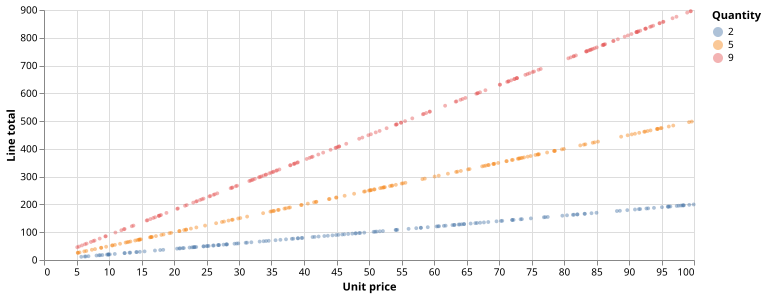

In [7]:
ex.total_plot(orders)

**Figure 1.** Recorded line totals versus unit price for quantities 2, 5, and 9.
The figure uses a fixed sample of 500 observations from those groups.

In [8]:
ex.local_models(report)

GT(_tbl_data=shape: (2, 3)
┌─────────────────────────┬────────────┬──────────────┐
│ Model                   ┆ Holdout R² ┆ Holdout rows │
│ ---                     ┆ ---        ┆ ---          │
│ str                     ┆ str        ┆ str          │
╞═════════════════════════╪════════════╪══════════════╡
│ One global linear model ┆ 0.876      ┆ 957          │
│ 8 local linear models   ┆ 0.998      ┆ 957          │
└─────────────────────────┴────────────┴──────────────┘, _body=<great_tables._gt_data.Body object at 0x115929b70>, _boxhead=Boxhead([ColInfo(var='Model', type=<ColInfoTypeEnum.default: 1>, column_label='Model', column_align='left', column_width=None, stub_level=None), ColInfo(var='Holdout R²', type=<ColInfoTypeEnum.default: 1>, column_label='Holdout R²', column_align='left', column_width=None, stub_level=None), ColInfo(var='Holdout rows', type=<ColInfoTypeEnum.default: 1>, column_label='Holdout rows', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10bcf96e0>, _spanners=Spanners([]), _heading=Heading(title='Table 5. Approximate models of line_total', subtitle='Both scores are taken from the same reported diagnostic holdout. Neither score establishes an exact accounting identity.', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x115950850>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x115950a50>, _source_notes=[], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Model', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Model', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Holdout R²', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Holdout R²', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Holdout rows', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Holdout rows', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')])], _locale=<great_tables._gt_data.Locale object at 0x1158ff820>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='100%'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='14px'), table_font_weight=OptionsInfo(scss=True, category='

R² compares prediction error with variation in the held-out values. A value closer to 1
means less unexplained variation on those evaluation rows.

The higher holdout R² supports a conditional description of the relationship.
It remains an approximate model. The direct calculation in Table 4 is the evidence for the
exact generating formula.

## 4. What do the missing dates mean?

The report identifies two missing business dates. We compare the observed dates with a
Monday–Friday calendar to identify them explicitly. Holidays are not excluded from this
reference calendar.

The fixture deliberately omits these dates. In operational data, an absent date could mean
no orders were placed or that observations were not recorded; the extract alone cannot
distinguish those explanations.

In [9]:
ex.missing_dates(orders, report)

GT(_tbl_data=shape: (2, 2)
┌──────────────────────────────┬─────────────────────────────────┐
│ Date absent from the extract ┆ Reference calendar              │
│ ---                          ┆ ---                             │
│ str                          ┆ str                             │
╞══════════════════════════════╪═════════════════════════════════╡
│ 2024-04-25                   ┆ Monday–Friday; holidays not ex… │
│ 2024-04-26                   ┆ Monday–Friday; holidays not ex… │
└──────────────────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x1158c8950>, _boxhead=Boxhead([ColInfo(var='Date absent from the extract', type=<ColInfoTypeEnum.default: 1>, column_label='Date absent from the extract', column_align='left', column_width=None, stub_level=None), ColInfo(var='Reference calendar', type=<ColInfoTypeEnum.default: 1>, column_label='Reference calendar', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x1158df9b0>, _spanners=Spanners([]), _heading=Heading(title='Table 6. Direct check of the date-gap finding', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x115a097c0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x115a099a0>, _source_notes=[], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Date absent from the extract', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Date absent from the extract', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Reference calendar', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Reference calendar', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')])], _locale=<great_tables._gt_data.Locale object at 0x1158df890>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='100%'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='14px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', valu

Other absences and representation issues are listed in Table 1: missing `support_hours`
values and two phone-number formats. The first is an absence of measurement; the second is
an inconsistency of representation. They require different treatment.

## 5. Does tenure contain information about churn?

The report identifies a predictive dependency of `churn` on `tenure_months`.
One source of evidence is a decision-table model. Its accuracy is compared with always
predicting the most common class. Five-fold cross-validation trains on four
parts of the data and evaluates the remaining part, repeated across the five parts.

Figure 2 shows the observed churn proportions. It describes the data; the validation score
in Table 1 comes from the reported model. Neither result establishes that changing tenure
would change churn.

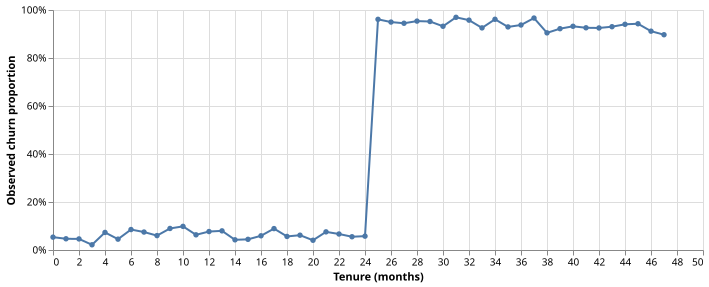

In [10]:
ex.churn_plot(orders)

**Figure 2.** Observed churn proportion at each tenure value. The generating rule changes
at 24 months and flips each label independently with probability 0.06. This is a controlled prediction example,
not an estimate of customer behavior from real observations.

We then permute the labels while leaving the predictors unchanged. The deliberately
constructed row-level relationship is removed. We check that the library no longer reports
churn as predictable. The independent numeric field provides a second negative control.

In [11]:
permuted = ex.permute_churn(orders)
permuted_report = onceover.profile(permuted)
ex.validation(orders, report, permuted_report)

GT(_tbl_data=shape: (5, 3)
┌─────────────────────────────┬─────────────────────────────────┬─────────────────────────────────┐
│ Check                       ┆ Expected                        ┆ Observed                        │
│ ---                         ┆ ---                             ┆ ---                             │
│ str                         ┆ str                             ┆ str                             │
╞═════════════════════════════╪═════════════════════════════════╪═════════════════════════════════╡
│ Internal order identifier   ┆ Unique and complete             ┆ Verified directly               │
│ External order reference    ┆ Three surplus repeated values   ┆ Direct count agrees with repor… │
│ Derived quantity            ┆ double_quantity = 2 × quantity  ┆ All rows agree                  │
│ Independent numeric control ┆ No reported predictability      ┆ No finding reported             │
│ Permuted churn labels       ┆ No reported churn prediction o… ┆ No finding reported             │
└─────────────────────────────┴─────────────────────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x1159ad390>, _boxhead=Boxhead([ColInfo(var='Check', type=<ColInfoTypeEnum.default: 1>, column_label='Check', column_align='left', column_width='27%', stub_level=None), ColInfo(var='Expected', type=<ColInfoTypeEnum.default: 1>, column_label='Expected', column_align='left', column_width='41%', stub_level=None), ColInfo(var='Observed', type=<ColInfoTypeEnum.default: 1>, column_label='Observed', column_align='left', column_width='32%', stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x1158479b0>, _spanners=Spanners([]), _heading=Heading(title='Table 7. Verification and negative controls', subtitle='The permutation is one fixed control, not an estimate of a false-positive rate.', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x11592a7b0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x115929a90>, _source_notes=[], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Check', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Check', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Check', rownum=2, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Check', rownum=3, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Check', rownum=4, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Expected', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Expected', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Expected', rownum=2, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Expected', rownum=3, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anyw

These controls test the examples in this notebook. A single permutation is not an estimate
of a false-positive rate. Because discovery and model selection use the same extract,
claims intended for use on new data require a separate validation design.

## 6. What did the diagnostic examine?

The report includes the scope of each pass. Some checks examine every row; relationship
searches can limit rows, predictors, candidates, or reported explanations. A completed pass
therefore does not imply an exhaustive search. An absent finding does not establish independence.

In [12]:
ex.coverage(report)

GT(_tbl_data=shape: (16, 3)
┌───────────────────────┬─────────────┬─────────────────────────────────┐
│ Pass                  ┆ Status      ┆ Recorded scope                  │
│ ---                   ┆ ---         ┆ ---                             │
│ str                   ┆ str         ┆ str                             │
╞═══════════════════════╪═════════════╪═════════════════════════════════╡
│ arithmetic identities ┆ ran_exact   ┆ 1 candidate pairs checked, 1 i… │
│ association rules     ┆ ran_sampled ┆ 3 of 3 nominal features (all e… │
│ column cards          ┆ ran_exact   ┆ 17 cards (exact)                │
│ dates                 ┆ ran_exact   ┆ 1 temporal columns, 1 gap even… │
│ decision tables       ┆ ran_sampled ┆ 6 categorical targets searched… │
│ …                     ┆ …           ┆ …                               │
│ prism rules           ┆ ran_sampled ┆ 6 targets eligible, 25 rules; … │
│ regimes               ┆ ran_sampled ┆ 3 of 3 eligible numeric target… │
│ row duplicates        ┆ ran_exact   ┆ no exact duplicate rows (exact… │
│ rule evaluation       ┆ ran_sampled ┆ 26 of 31 candidates passed a c… │
│ sortedness            ┆ ran_exact   ┆ 2 columns sorted by row order   │
└───────────────────────┴─────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x115903140>, _boxhead=Boxhead([ColInfo(var='Pass', type=<ColInfoTypeEnum.default: 1>, column_label='Pass', column_align='left', column_width='23%', stub_level=None), ColInfo(var='Status', type=<ColInfoTypeEnum.default: 1>, column_label='Status', column_align='left', column_width='16%', stub_level=None), ColInfo(var='Recorded scope', type=<ColInfoTypeEnum.default: 1>, column_label='Recorded scope', column_align='left', column_width='61%', stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x1158f9480>, _spanners=Spanners([]), _heading=Heading(title='Table 8. Scope of the diagnostic', subtitle='The scope records which rows, features, and candidate relationships were examined.', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x1159124e0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x1158c9490>, _source_notes=[], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Pass', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Pass', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Pass', rownum=2, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Pass', rownum=3, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Pass', rownum=4, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Pass', rownum=5, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Pass', rownum=6, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Pass', rownum=7, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=No

## Column reference

Table 9 gives the full field inventory. Inferred roles are descriptive suggestions.
For example, a continuous measurement can happen to be unique without being a meaningful
identifier. Field definitions and generating rules are in the companion module.

In [13]:
ex.columns(report)

GT(_tbl_data=shape: (17, 5)
┌──────────────────┬─────────┬───────────────┬─────────┬──────────┐
│ Field            ┆ Type    ┆ Inferred role ┆ Missing ┆ Distinct │
│ ---              ┆ ---     ┆ ---           ┆ ---     ┆ ---      │
│ str              ┆ str     ┆ str           ┆ str     ┆ str      │
╞══════════════════╪═════════╪═══════════════╪═════════╪══════════╡
│ churn            ┆ int64   ┆ categorical   ┆ 0       ┆ 2        │
│ control          ┆ float64 ┆ identifier    ┆ 0       ┆ 8,000    │
│ country          ┆ string  ┆ categorical   ┆ 0       ┆ 4        │
│ double_quantity  ┆ int64   ┆ categorical   ┆ 0       ┆ 10       │
│ line_total       ┆ float64 ┆ continuous    ┆ 0       ┆ 7,136    │
│ …                ┆ …       ┆ …             ┆ …       ┆ …        │
│ source_order_ref ┆ string  ┆ free_text     ┆ 0       ┆ 7,997    │
│ status_code      ┆ int64   ┆ categorical   ┆ 0       ┆ 5        │
│ support_hours    ┆ float64 ┆ categorical   ┆ 416     ┆ 41       │
│ tenure_months    ┆ int64   ┆ categorical   ┆ 0       ┆ 48       │
│ unit_price       ┆ float64 ┆ continuous    ┆ 0       ┆ 5,441    │
└──────────────────┴─────────┴───────────────┴─────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x115946430>, _boxhead=Boxhead([ColInfo(var='Field', type=<ColInfoTypeEnum.default: 1>, column_label='Field', column_align='left', column_width='27%', stub_level=None), ColInfo(var='Type', type=<ColInfoTypeEnum.default: 1>, column_label='Type', column_align='left', column_width='15%', stub_level=None), ColInfo(var='Inferred role', type=<ColInfoTypeEnum.default: 1>, column_label='Inferred role', column_align='left', column_width='25%', stub_level=None), ColInfo(var='Missing', type=<ColInfoTypeEnum.default: 1>, column_label='Missing', column_align='left', column_width='16%', stub_level=None), ColInfo(var='Distinct', type=<ColInfoTypeEnum.default: 1>, column_label='Distinct', column_align='left', column_width='17%', stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x115951450>, _spanners=Spanners([]), _heading=Heading(title='Table 9. Column summaries', subtitle='Roles are heuristics. Uniqueness alone does not establish that a field is a business identifier.', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x1158c9850>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x1159ad440>, _source_notes=[], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Field', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Field', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Field', rownum=2, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Field', rownum=3, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Field', rownum=4, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Field', rownum=5, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Field', rownum=6, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpn

## Reproducibility

The order fixture uses seed 2024; the label permutation uses seed 2025. The code below checks
that the same input and configuration produce identical report JSON. The complete findings
and their evidence remain available in `report.findings` and `report.data`.

Run this notebook from its directory with the companion file present. Dependencies are
included in `onceover[notebook]`.

In [14]:
assert report.to_json() == onceover.profile(orders).to_json()
ex.table([{"Component": "onceover", "Version": onceover.__version__},
          {"Component": "Polars", "Version": ex.pl.__version__}],
         "Software versions")

GT(_tbl_data=shape: (2, 2)
┌───────────┬─────────┐
│ Component ┆ Version │
│ ---       ┆ ---     │
│ str       ┆ str     │
╞═══════════╪═════════╡
│ onceover  ┆ 0.1.0   │
│ Polars    ┆ 2.0.0   │
└───────────┴─────────┘, _body=<great_tables._gt_data.Body object at 0x11590fd10>, _boxhead=Boxhead([ColInfo(var='Component', type=<ColInfoTypeEnum.default: 1>, column_label='Component', column_align='left', column_width=None, stub_level=None), ColInfo(var='Version', type=<ColInfoTypeEnum.default: 1>, column_label='Version', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x115952450>, _spanners=Spanners([]), _heading=Heading(title='Software versions', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x1159ad860>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x11594b6b0>, _source_notes=[], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Component', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Component', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Version', rownum=0, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')]), StyleInfo(locname=LocBody(columns=None, rows=None, mask=None), grpname=None, colname='Version', rownum=1, colnum=None, styles=[CellStyleCss(rule='white-space: normal; overflow-wrap: anywhere; line-height: 1.5;')])], _locale=<great_tables._gt_data.Locale object at 0x115952650>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='100%'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='14px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_borde